# Latent Space Interpretation: Axis Ranking and GMM Component Biology

This notebook demonstrates how to interpret a trained GGML latent space
using data processed by the Snakemake benchmark pipeline.

It loads:
1. The **fitted GMM** from the pipeline's `gmm/` output
2. The **trained metric** from the pipeline's `benchmark/` output (GMM_DiagBures)

Then runs:
- Latent axis gene ranking and pathway enrichment
- GMM component cell-type summaries and pathway enrichment

In [1]:
import json
import pickle
import sys
from pathlib import Path

import matplotlib
import pandas as pd
import scanpy as sc
import yaml

import ggml_ot

# Same matplotlib settings as the pipeline (TrueType fonts in PDFs, see snakemake/config/matplotlibrc)
matplotlib.rc_file("../snakemake/config/matplotlibrc", use_default_template=False)

# Make snakemake pipeline utilities importable
sys.path.insert(0, str(Path("../snakemake/scripts").resolve()))
from _utils import (
    get_gmm_key,
    get_dataset_use_rep,
    get_dataset_construction_params,
    get_method_train_test_kwargs,
    get_method_tune_kwargs,
    get_bench_hash,
    get_tune_hash,
    build_dataset,
    apply_runtime_settings,
)

## Configuration

Set the dataset name and config file. The pipeline utilities derive all paths
(GMM key, tuning hash, benchmark hash) from the config.

In [2]:
dataset_name = "myocardial_infarction" #COVID" #
method_name = "GMM_DiagBures"
config_file = "config/paper/main_benchmark.yml"

# --- Load and merge pipeline config (defaults + experiment overlay) ----------

snakemake_dir = Path("../snakemake").resolve()
repo_root = snakemake_dir.parent

def display_path(path: Path) -> Path:
    return Path("..") / Path(path).resolve().relative_to(repo_root)

def deep_merge(base, override):
    """Recursive dict merge (mimics Snakemake's configfile merging)."""
    result = dict(base)
    for k, v in override.items():
        if k in result and isinstance(result[k], dict) and isinstance(v, dict):
            result[k] = deep_merge(result[k], v)
        else:
            result[k] = v
    return result

with open(snakemake_dir / "config/defaults.yml") as f:
    config = yaml.safe_load(f)
with open(snakemake_dir / config_file) as f:
    config = deep_merge(config, yaml.safe_load(f))

datasets_file = snakemake_dir / "config" / config["datasets_file"]
with open(datasets_file) as f:
    config["datasets"] = yaml.safe_load(f)["datasets"]

data_root = (snakemake_dir / config["data_root"]).resolve()
ds_meta = config["datasets"][dataset_name]
method_cfg = config["methods"][method_name]

apply_runtime_settings(config)

## Derive pipeline paths and load data

Compute the GMM key, tuning hash, and benchmark hash using the same
`_utils` functions the Snakemake rules use.

In [3]:
gmm_key = get_gmm_key(config, ds_meta)
ds_params = get_dataset_construction_params(config, ds_meta, method_cfg, gmm_key)

# Locate GMM-fitted h5ad
h5ad_path = data_root / dataset_name / "gmm" / f"{gmm_key}.h5ad"
assert h5ad_path.exists(), f"GMM h5ad not found: {display_path(h5ad_path)}"

# Locate tuned hyperparameters
tune_grid = get_method_tune_kwargs(config, method_name)
tune_h = get_tune_hash(method_name, tune_grid, ds_params)
tuned_params_path = data_root / dataset_name / "tune" / method_name / tune_h / "best_params.json"
assert tuned_params_path.exists(), f"Tuned params not found: {display_path(tuned_params_path)}"

with open(tuned_params_path) as f:
    tuned_params = json.load(f)

# Locate benchmark outputs (trained metric)
train_kw = get_method_train_test_kwargs(config, method_name)
bench_h = get_bench_hash(method_name, train_kw, ds_params)
bench_dir = data_root / dataset_name / "benchmark" / method_name / bench_h

if not bench_dir.exists():
    # Fallback: pick the most recent benchmark directory
    available = sorted((data_root / dataset_name / "benchmark" / method_name).iterdir())
    bench_dir = available[-1]
    print(f"Computed hash {bench_h} not found; falling back to {bench_dir.name}")

metric_path = bench_dir / "trained_metric.pkl"
scores_path = bench_dir / "scores.csv"

print(f"GMM key:        {gmm_key}")
print(f"Tuned params:   {tuned_params}")
print(f"Benchmark dir:  {bench_dir.name}")
print(f"h5ad:           {display_path(h5ad_path)}")
print(f"metric:         {display_path(metric_path)}")

GMM key:        gmm_X_pca_100_norm_full_a860b950
Tuned params:   {'alpha': 1, 'mi_reg': 0.0001, 'n_comps': 5, 'reg': 0.0001, 'reg_type': 'fro'}
Benchmark dir:  ddad5f79
h5ad:           ../data/snakemake/myocardial_infarction/gmm/gmm_X_pca_100_norm_full_a860b950.h5ad
metric:         ../data/snakemake/myocardial_infarction/benchmark/GMM_DiagBures/ddad5f79/trained_metric.pkl


In [4]:
# Load the AnnData with fitted GMM and build the GGML dataset
adata = sc.read_h5ad(h5ad_path)
dataset = build_dataset(adata, config, ds_meta, method_cfg, gmm_key)

# Load and apply the trained GGML metric
# This populates adata.obsm["X_ggml"] and adata.varm["W_ggml"]
with open(metric_path, "rb") as f:
    metric = pickle.load(f)

dataset.map_A = metric["best"]

print(f"Cells: {adata.n_obs}, Genes: {adata.n_vars}")
print(f"Patients: {adata.obs[ds_meta['patient_col']].nunique()}")
print(f"Labels: {adata.obs[ds_meta['label_col']].unique().tolist()}")
print(f"X_ggml shape: {adata.obsm['X_ggml'].shape}")
print(f"W_ggml shape: {adata.varm['W_ggml'].shape}")

Cells: 191795, Genes: 28975
Patients: 29
Labels: ['myogenic', 'ischemic', 'fibrotic']
X_ggml shape: (191795, 5)
W_ggml shape: (28975, 5)


In [5]:
# Benchmark scores from this run
scores_df = pd.read_csv(scores_path, header=[0, 1], index_col=0)
ggml_ot.pl.table(scores_df)

metric        knn                ari           ari_complete            \
mean±SD      mean       SD      mean        SD         mean        SD   
0        0.933333  0.08165  0.963816  0.044317     0.963816  0.044317   

metric  silhouette           full_ot_time(s)           inf_time(ms)           \
mean±SD       mean        SD            mean        SD         mean       SD   
0          0.54475  0.021954         0.27732  0.001161     0.683055  0.00286   

metric  epoch_time(s)            
mean±SD          mean        SD  
0             0.35988  0.005238

## 1. Rank Latent Axes

`adata.varm["W_ggml"]` contains the gene-space loading matrix (genes x latent dims).
`dataset.rank_latent_axes()` returns a tidy DataFrame with signed gene scores per axis.

In [6]:
ggml_ot.gene.top_ranked(adata,n_genes=50,gene_symbols="feature_name")

array([['DDX5', 'NAV1', 'WWOX', 'TNS1', 'DISC1', 'FOXO3', 'SH3D19',
        'AUTS2', 'TMTC1', 'ITPR2', 'CLIC4', 'EIF4G3', 'HIF1A', 'KALRN',
        'DIAPH2', 'GOLGA4', 'ANKRD17', 'HIF3A', 'NAV2', 'MRTFA', 'PDK4',
        'LRRFIP1', 'OSMR', 'DLEU2', 'COL4A1', 'ATXN1', 'BTBD9', 'AOPEP',
        'MIR99AHG', 'ATG7', 'PDE7B', 'PAFAH1B1', 'SLCO3A1', 'VCL',
        'PDS5A', 'PLPP1', 'FRY', 'CTNNA3', 'FHL2', 'SGCD', 'MAML3',
        'MYH7', 'RALGAPA1', 'MYO9B', 'PDLIM3', 'RAPGEF2', 'PPP3CA',
        'RYR2', 'PRKCE', 'ARHGAP24'],
       ['EIF4G3', 'ZNF609', 'VMP1', 'GRK5', 'MRTFA', 'NRP1', 'GSN',
        'MIR99AHG', 'FGD4', 'EXT1', 'RBMS3', 'MYH7', 'CELF2', 'IGFBP7',
        'FOXP1', 'RBMS1', 'SASH1', 'ANKRD1', 'SPTBN1', 'FKBP5', 'TIMP3',
        'ZCCHC7', 'LHFPL6', 'PICALM', 'PLCG2', 'ZMIZ1', 'CSGALNACT1',
        'PLXDC2', 'ZBTB20', 'DCN', 'NEXN', 'UBE2K', 'NFIA', 'SMYD3',
        'NFIB', 'MT-ATP6', 'AOPEP', 'AUTS2', 'PBX1', 'FOXO3', 'PPP3CA',
        'CARMIL1', 'CTNND1', 'REV3L', 'COL3A1', '

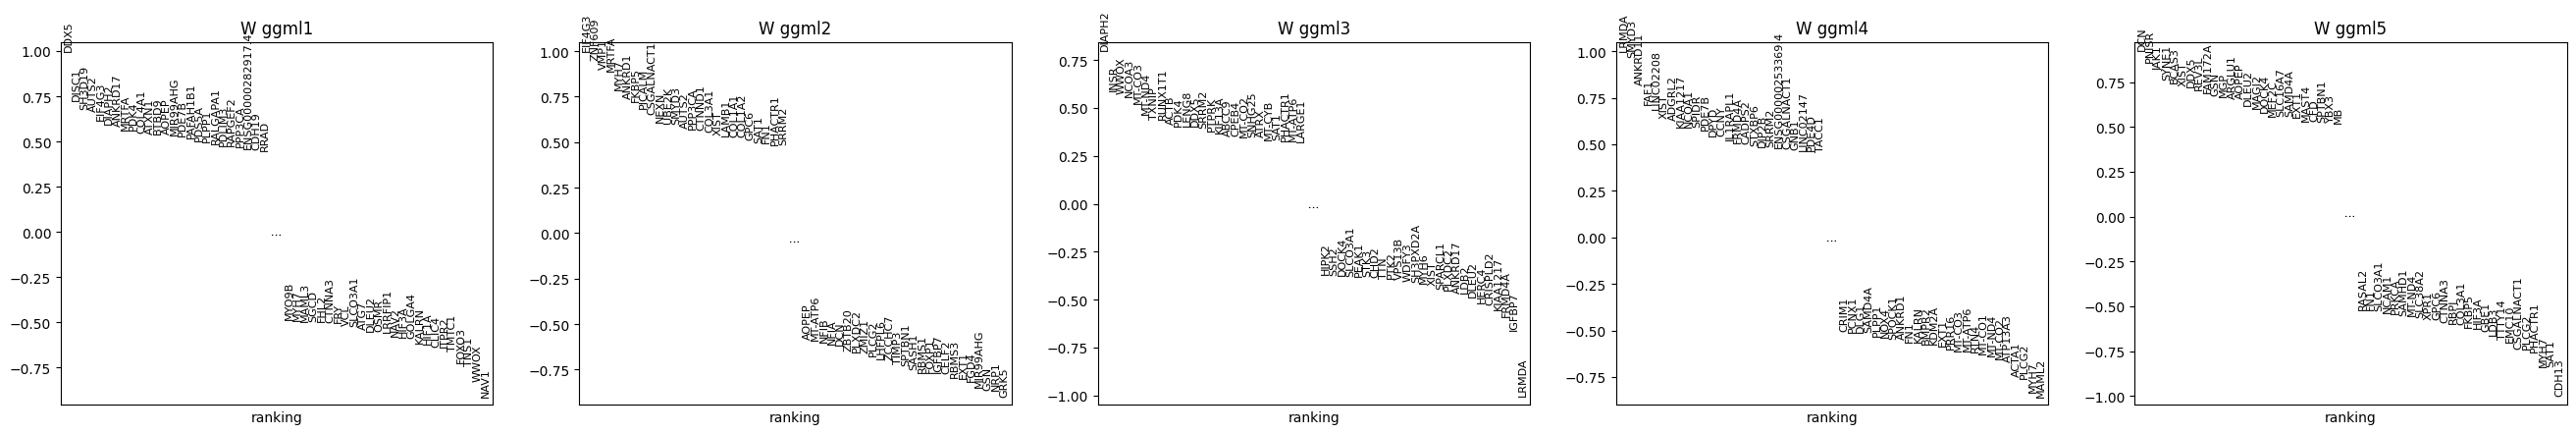

In [7]:
top_genes = ggml_ot.gene.ranking(adata,n_genes=50,gene_symbols="feature_name")

In [8]:
n_comps = adata.varm["W_ggml"].shape[1]

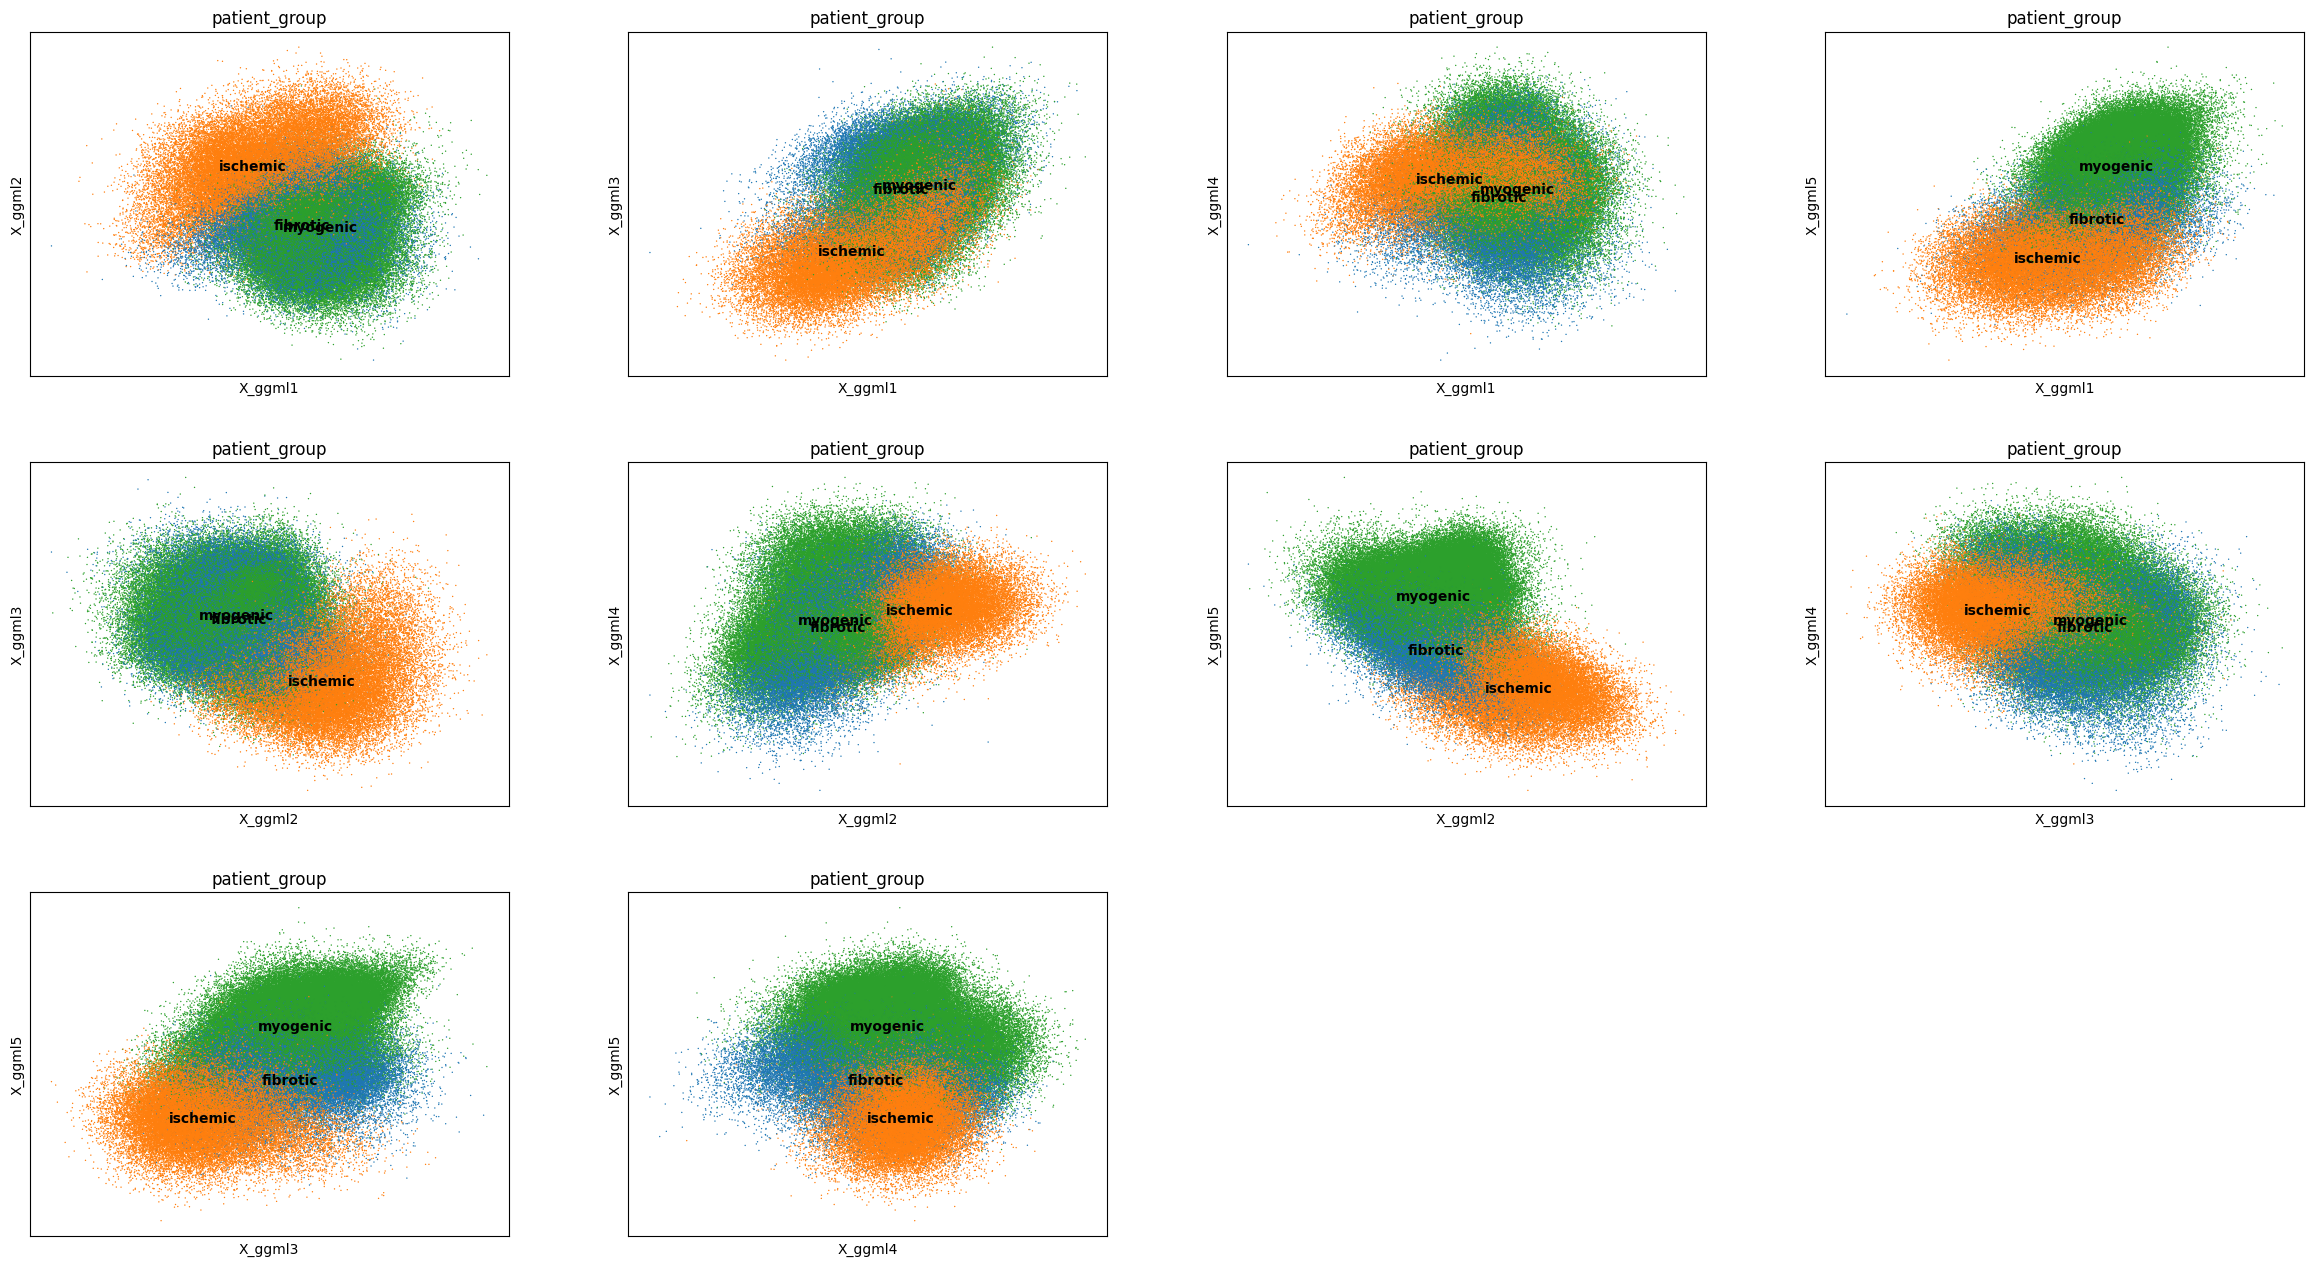

In [9]:
component_pairs = [f"{i},{j}" for i in range(1, n_comps+1) for j in range(1, n_comps+1) if j > i]
sc.pl.embedding(adata,basis="X_ggml",color=["patient_group"],components=component_pairs,s=4,legend_loc="on data") 

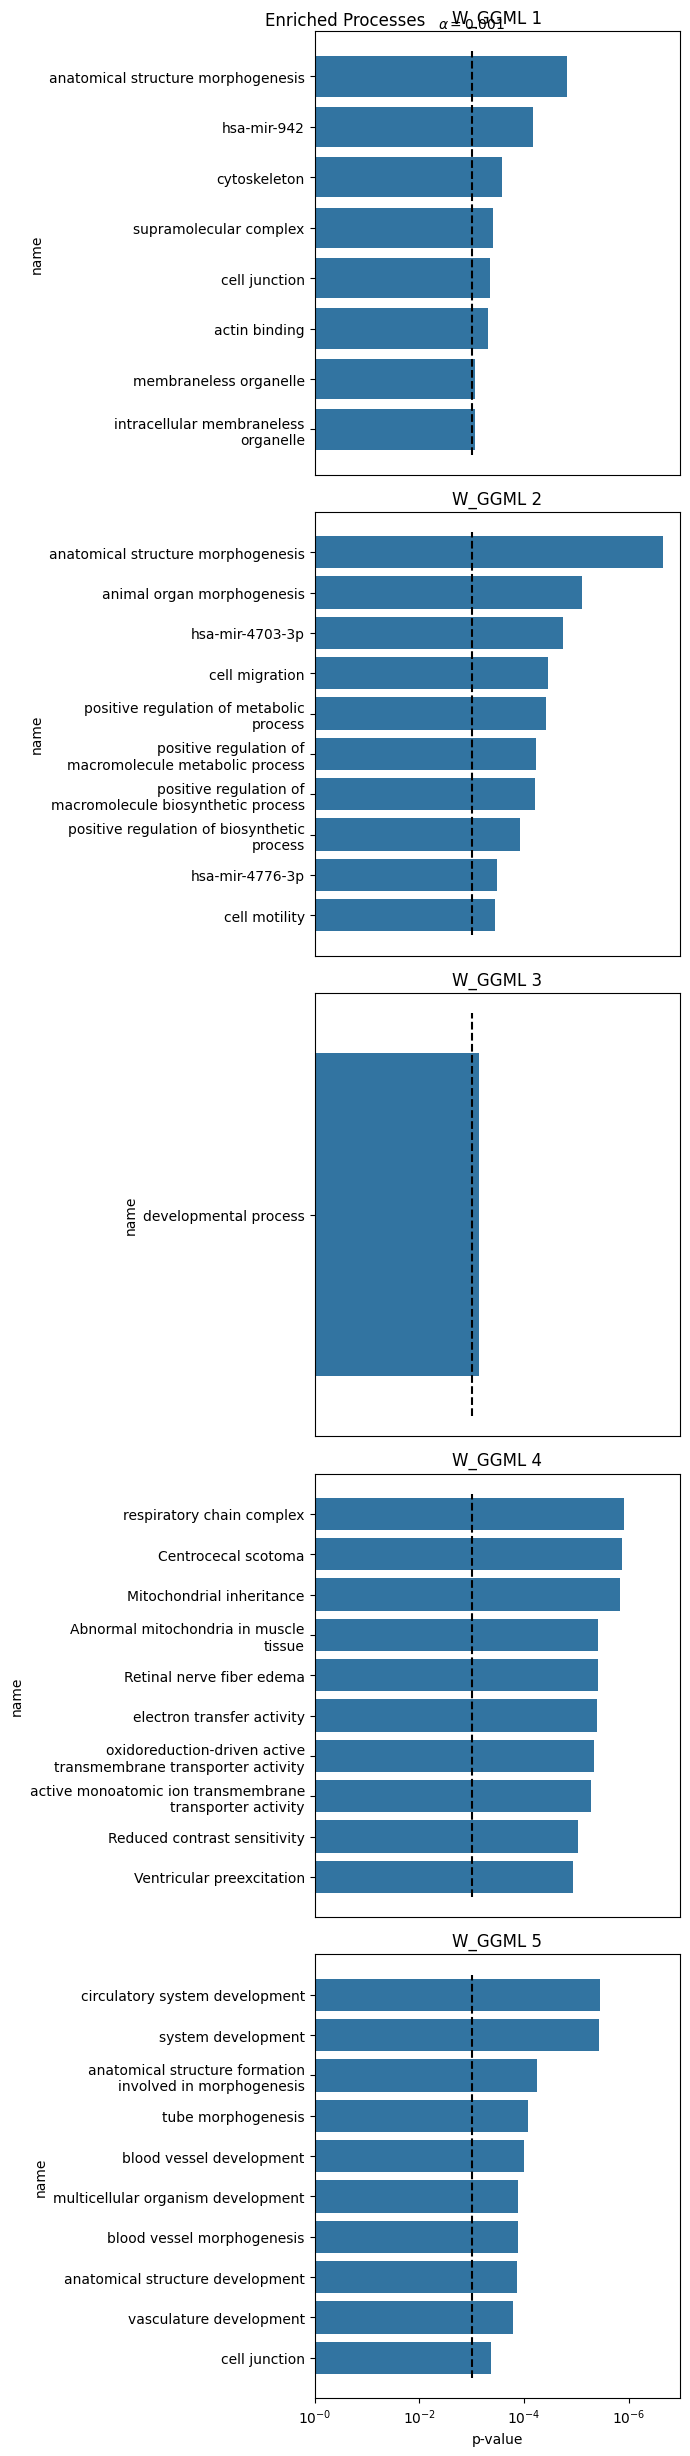

In [10]:
n_genes = 50
ggml_ot.gene.enrichment(adata, gene_symbols="feature_name", ordered=True, n_genes=n_genes, alpha=0.001,max_terms=10, log_axis=True)

## Select components to analyze in detail

In [11]:
selected_components = [2, 5]
selected_components_str = ",".join(map(str, selected_components))

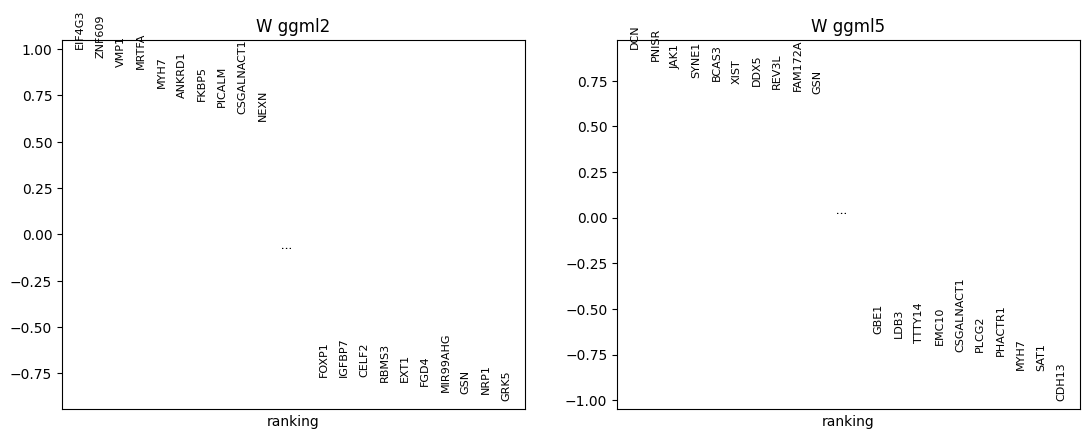

In [12]:
top_genes = ggml_ot.gene.ranking(adata,n_genes=20,gene_symbols="feature_name",components=selected_components)

In [13]:
ggml_ot.gene.top_ranked(adata,n_genes=100,gene_symbols="feature_name",components=selected_components)

array([['EIF4G3', 'ZNF609', 'VMP1', 'GRK5', 'MRTFA', 'NRP1', 'GSN',
        'MIR99AHG', 'FGD4', 'EXT1', 'RBMS3', 'MYH7', 'CELF2', 'IGFBP7',
        'FOXP1', 'RBMS1', 'SASH1', 'ANKRD1', 'SPTBN1', 'FKBP5', 'TIMP3',
        'ZCCHC7', 'LHFPL6', 'PICALM', 'PLCG2', 'ZMIZ1', 'CSGALNACT1',
        'PLXDC2', 'ZBTB20', 'DCN', 'NEXN', 'UBE2K', 'NFIA', 'SMYD3',
        'NFIB', 'MT-ATP6', 'AOPEP', 'AUTS2', 'PBX1', 'FOXO3', 'PPP3CA',
        'CARMIL1', 'CTNND1', 'REV3L', 'COL3A1', 'SAMD4A', 'XIST',
        'LAMB1', 'COL1A1', 'COL1A2', 'NAV2', 'TCF4', 'GPC6', 'CTBP2',
        'ABLIM1', 'SAT1', 'SH3RF3', 'FN1', 'FSTL1', 'STARD13', 'ELN',
        'PTPRG', 'PHACTR1', 'SRRM2', 'TNXB', 'OGA', 'DLG2', 'IMMP2L',
        'NCOR2', 'MAML2', 'SERPINE1', 'ASCC3', 'CHD9', 'PALM2AKAP2',
        'SLC2A13', 'SORBS1', 'LAMA2', 'LIMCH1', 'ACTC1', 'MBNL1',
        'POSTN', 'PLCB4', 'HSP90AA1', 'MECOM', 'PDE4D', 'MGP', 'HEG1',
        'RIN2', 'MT-CYB', 'HIPK3', 'RUNX1T1', 'BAZ2B', 'CUX1', 'ATP2B4',
        'SH3PXD2B', '

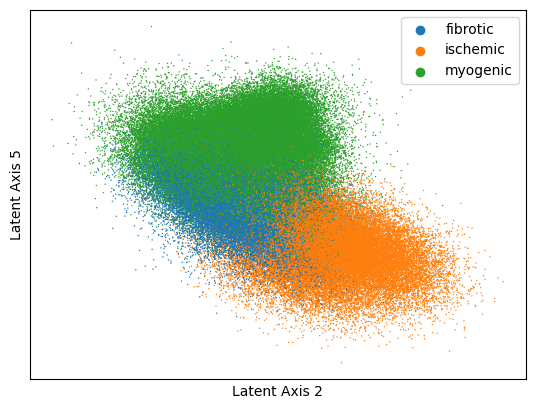

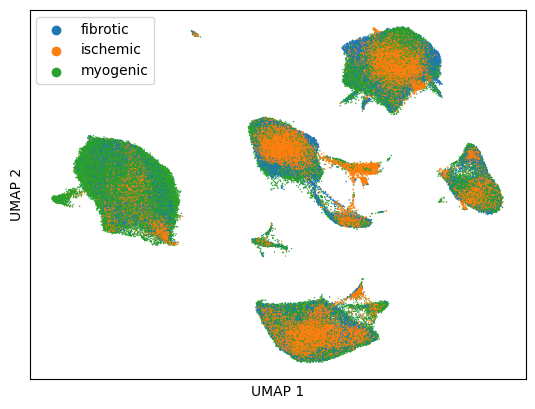

In [14]:
# Latent Embedding
ax1 = sc.pl.embedding(adata,basis="X_ggml",color=["patient_group"],title="",components=selected_components_str,s=4,legend_loc="best",show=False) 

# Change axis labels to indicate which components are plotted
ax1.set_xlabel(f"Latent Axis {selected_components[0]}")
ax1.set_ylabel(f"Latent Axis {selected_components[1]}")

# Latent Embedding
ax2 = sc.pl.embedding(adata,basis="X_umap",color=["patient_group"],title="",s=4,legend_loc="best",show=False) 

# Change axis labels to indicate which components are plotted
ax2.set_xlabel(f"UMAP 1")
ax2.set_ylabel(f"UMAP 2")

# Save each axis (copied into paper/ by make sync-paper-assets)
out_dir = Path("../data/generated_plots/interpretability")
out_dir.mkdir(parents=True, exist_ok=True)
ax1.figure.savefig(out_dir / "latent_space.png", dpi=300, bbox_inches="tight")
ax2.figure.savefig(out_dir / "umap_space.png", dpi=300, bbox_inches="tight")

Axis 2 positive
  complex of collagen trimers: p=1.5e-08, genes=COL3A1, COL1A1, COL1A2, COL5A2, COL6A3, COL4A1
  ECM proteoglycans: p=1.7e-08, genes=COL3A1, LAMB1, COL1A1, COL1A2, FN1, SERPINE1, COL5A2, COL6A3, COL4A1
  extracellular matrix structural constituent: p=2.1e-07, genes=COL3A1, LAMB1, COL1A1, COL1A2, FN1, POSTN, COL5A2, COL6A3, COL4A1
Axis 5 negative
  blood vessel development: p=8.9e-10, genes=CDH13, SAT1, EMC10, HIF3A, COL3A1, RBPJ, PRKCA, FN1, SGCD, COL1A2, RORA, HSPB1, STAB1, RUNX1, RNF213, FOXO1, PDE3B, SERPINE1, ROCK1, HIF1A, TYMP, HIPK2, PRICKLE1
  vasculature development: p=2.1e-09, genes=CDH13, SAT1, EMC10, HIF3A, COL3A1, RBPJ, PRKCA, FN1, SGCD, COL1A2, RORA, HSPB1, STAB1, RUNX1, RNF213, FOXO1, PDE3B, SERPINE1, ROCK1, HIF1A, TYMP, HIPK2, PRICKLE1
  blood vessel morphogenesis: p=2.1e-08, genes=CDH13, SAT1, EMC10, HIF3A, COL3A1, RBPJ, PRKCA, FN1, SGCD, RORA, HSPB1, STAB1, RUNX1, RNF213, PDE3B, SERPINE1, ROCK1, HIF1A, TYMP, HIPK2


.venv/lib/python3.11/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


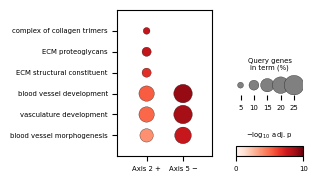

In [15]:
# Enrichment of the 100 genes with the largest loadings toward the ischemic samples
# (positive on latent axis 2, negative on latent axis 5), see _utils/fig6_enrichment.py.
# _utils/ is imported by path because the name _utils is taken by snakemake/scripts/_utils.py.
sys.path.insert(0, str(Path("_utils").resolve()))
from fig6_enrichment import enrichment_dotplot

enrich = enrichment_dotplot(adata, ends=[(2, "+"), (5, "-")], n_genes=100, n_terms=3,
                            max_gene_set_size=1000, vertical=True, figsize=(2.4, 1.9),
                            save=out_dir / "enrichment_dotplot.pdf")

Axis 1 positive
  central region of growth cone: p=4.5e-04, genes=DISC1, PAFAH1B1
  glutamatergic synapse: p=5.4e-04, genes=DISC1, MRTFA, BTBD9, PAFAH1B1, PPP3CA, NF1, BRAF, EPS15
  regulation of neurogenesis: p=7.2e-03, genes=DISC1, PAFAH1B1, RAPGEF2, PPP3CA, NF1, BRAF, CUX1
Axis 1 negative
  anchoring junction: p=9.5e-07, genes=WWOX, TNS1, CLIC4, VCL, CTNNA3, FHL2, ARHGAP24, CDH13, SLC8A1, PHLDB2, FRMD4A, SH3PXD2A, SYNE2, FCHSD2
  actin filament-based movement: p=1.4e-06, genes=CTNNA3, SGCD, MYH7, MYO9B, RYR2, TTN, FGF12, SYNE2
  heart contraction: p=4.3e-06, genes=CTNNA3, SGCD, MYH7, RYR2, TTN, SLC8A1, FGF12, EXT1, EPAS1, ASPH, MYL2, ACTC1
Axis 2 positive
  complex of collagen trimers: p=1.5e-08, genes=COL3A1, COL1A1, COL1A2, COL5A2, COL6A3, COL4A1
  ECM proteoglycans: p=1.7e-08, genes=COL3A1, LAMB1, COL1A1, COL1A2, FN1, SERPINE1, COL5A2, COL6A3, COL4A1
  extracellular matrix structural constituent: p=2.1e-07, genes=COL3A1, LAMB1, COL1A1, COL1A2, FN1, POSTN, COL5A2, COL6A3, COL4A1
A

.venv/lib/python3.11/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


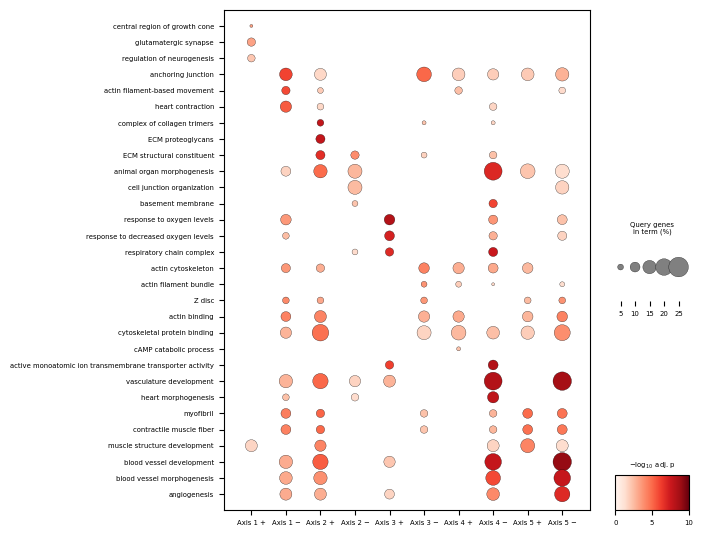

In [16]:
# Same enrichment for both ends of all latent axes (appendix figure)
all_ends = [(axis, sign) for axis in range(1, n_comps + 1) for sign in ("+", "-")]
enrich_all = enrichment_dotplot(adata, ends=all_ends, n_genes=100, n_terms=3,
                                max_gene_set_size=1000, vertical=True, figsize=(6.0, 6.5),
                                save=out_dir / "enrichment_dotplot_all_axes.pdf")